In [1]:
import pandas as pd
import openmeteo_requests
import requests_cache
from retry_requests import retry

# Pocasi

In [9]:
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

url = "https://archive-api.open-meteo.com/v1/archive"

def setWeather(lat,lon,date):
    params = {
	"latitude": lat,
	"longitude": lon,
	"start_date": date,
	"end_date": date,
	"hourly": ["temperature_2m", "rain", "snowfall"],
	"timezone": "Europe/Berlin",
}
    responses = openmeteo.weather_api(url, params=params)

    response = responses[0]
 

    # Process hourly data. The order of variables needs to be the same as requested.
    hourly = response.Hourly()
    hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
    hourly_rain = hourly.Variables(1).ValuesAsNumpy()
    hourly_snowfall = hourly.Variables(2).ValuesAsNumpy()

    hourly_data = {"date": pd.date_range(
	    start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
	    end = pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
	    freq = pd.Timedelta(seconds = hourly.Interval()),
	    inclusive = "left"
    )}

    hourly_data["temperature_2m"] = hourly_temperature_2m
    hourly_data["rain"] = hourly_rain
    hourly_data["snowfall"] = hourly_snowfall

    hourly_dataframe = pd.DataFrame(data = hourly_data)
    return hourly_dataframe
    #return hourly_dataframe[hourly_dataframe["date"].dt.hour==hour]
    time.sleep(0.2)
    
def setData():
   
    i=0
    for index, row in ox.iterrows():
        
        if(pd.isnull(row["snehovaPokryvkaMaxApi"]) and i<590):             
             weatherAll=setWeather(row["wgsY"],row["wgsX"],row["datum"])
             weatherDF=weatherAll[weatherAll["date"].dt.hour==row["hodina"]]
             
             i=i+1
             
             ox.at[index,"teplotaPrumApi"]=weatherAll["temperature_2m"].mean()
             ox.at[index,"srazkyPrumApi"]=weatherAll["rain"].mean()
             ox.at[index,"snehovaPokryvkaPrumApi"]=weatherAll["snowfall"].mean()

             ox.at[index,"teplotaMaxApi"]=weatherAll["temperature_2m"].max()
             ox.at[index,"srazkyMaxApi"]=weatherAll["rain"].max()
             ox.at[index,"snehovaPokryvkaMaxApi"]=weatherAll["snowfall"].max()
            
             #if(len(weatherDF["temperature_2m"])!=0):   
                #ox.at[index,"teplotaApi"]=weatherDF["temperature_2m"]
                #ox.at[index,"srazkyApi"]=weatherDF["rain"]
                #ox.at[index,"snehovaPokryvkaApi"]=weatherDF["snowfall"]

          

In [3]:
ox=pd.read_csv("dfTest.csv",sep=";")

C:\Users\dkuch\AppData\Local\Temp\ipykernel_12980\1298545317.py:1: DtypeWarning: Columns (0: cisloKomunikace) have mixed types. Specify dtype option on import or set low_memory=False.
  ox=pd.read_csv("dfTest.csv",sep=";")


In [4]:
ox=ox.dropna(subset=['wgsY', 'wgsX'])

In [10]:
setData()

# Zatacky

In [11]:
import numpy
import pandas as pd
import math
import json
import geopy.distance

def getBearing(p1,p2):
    pRad1=[]
    pRad2=[]
    
    for rad in range(len(p1)):        
        pRad1.append(math.radians(p1[rad]))
        
    for rad in range(len(p2)):
        pRad2.append(math.radians(p2[rad]))      

    dLon=(pRad2[1]-pRad1[1])
    
    x=math.cos(pRad2[0]) * math.sin(dLon)
    y=math.cos(pRad1[0]) * math.sin(pRad2[0]) - math.sin(pRad1[0]) * math.cos(pRad2[0]) * math.cos(dLon)
    
    bearing = numpy.arctan2(x,y)
    bearing = (numpy.degrees(bearing)+360)%360
    
    return bearing

def getCurvatures(coor):
    degree=0
    coorCurvatures=[]
    coorCurvatures.append([coor[0],0,0])
    for corIndex in range(len(coor)):
        if(corIndex>=len(coor)-1):
            break
        if(coor[corIndex]==coor[corIndex+1]):
            continue
        az=int(getBearing(coor[corIndex],coor[corIndex+1]))
        if(corIndex==0):
            degree=0
        elif((coorCurvatures[-1][1]>=0 and coorCurvatures[-1][1]<=90 and (az>270)) ):
            degree=360+coorCurvatures[-1][1]-az
        elif (az>=0 and az<=90 and (coorCurvatures[-1][1]>=270)):
            degree=360+az-coorCurvatures[-1][1]

        else:
            degree=abs(az-int(coorCurvatures[-1][1]))
        coorCurvatures.append([coor[corIndex+1],int(az),int(degree)])

    return coorCurvatures

def findFourthQuartile(d1,d2):
    if(d1>=0 and d1<=90 and (d2>=270)):
        return 0
    
    if(d2>=0 and d2<=90 and (d1>=270)):
        return 1
    
    return -1

startQ=-1
trend=-1
startDegree=0
nextDegree=0
increase=2

def getQuartilee(degree):
    return int((degree-1)/90)

def getQuartile(c1,c2):
    quartileResult=findFourthQuartile(c1[1],c2[1])     

    global trend,startFQ
    
    if(trend==-1):  
             
        startFQ=getQuartilee(c1[1])

        if(quartileResult!=-1):            
            if(quartileResult==0):
                trend=0
            else:
                trend=1

        else:            
            
            if(c2[1]>c1[1]):
                trend=1                
            else:
                trend=0
        
        return True

    else:
        match trend:

            case 0:
                if(quartileResult==0):
                    return True
                
                if(c2[1]+increase<c1[1] and quartileResult!=1):
                    return True
                
            case 1:
                if(quartileResult==1):
                    return True

                if(c1[1]+increase<c2[1] and quartileResult!=0):
                    return True
    trend=-1            
    return False    

def findCurvatures(coor,stepDegree,maxDistance,md): 
    global trend
    pointChange=0
    firstIndex=-1
    lastDegree=0
    count=0
    actualDegree=0
    distance=0
    firstC=[]
    secondC=[]
    lastC=[]
    maxDegree=0
    
    lastC.append(0)
    lastC.append(0)
    lastC.append(0)
    lastC.append(0)

    coor[0].append(0)
    coor[0].append(0)
    coor[0].append(0)
    coor[0].append(0)
    coor[0].append(-1)

    for cIndex in range(len(coor)):        
        if(cIndex==len(coor)-1):
            break
      
        lastC=coor[cIndex+1]
        
        if(len(lastC)<=3):            
            lastC.append(0)
            lastC.append(0)
            lastC.append(0)
            lastC.append(0)
            lastC.append(-1)

        actualDegree=lastC[2]   
                
        if(actualDegree>=stepDegree and geopy.distance.geodesic(coor[cIndex][0],coor[cIndex+1][0]).meters<=maxDistance and getQuartile(coor[cIndex],coor[cIndex+1])):
            if(len(firstC)==0):
                firstC=coor[cIndex]
                
                firstIndex=cIndex
                secondC=coor[cIndex+1]
            count=count+1 
            secondC=coor[cIndex+1]
            distance=distance+geopy.distance.geodesic(coor[cIndex][0],coor[cIndex+1][0]).meters
                     
            maxDegree=maxDegree+actualDegree
            
        else:
            if(maxDegree!=0):
                if(maxDegree>=md): 
                    #distance=geopy.distance.geodesic(firstC[0],secondC[0]).meters                     
                    firstC[3]=maxDegree
                    firstC[5]=distance
                    firstC[7]=pointChange

                    coor[cIndex][4]=maxDegree 
                    coor[cIndex][6]=distance
                    coor[cIndex][7]=pointChange

                    for a in range(firstIndex+1,cIndex):
                        coor[a][4]=maxDegree 
                        coor[a][6]=distance
                        coor[a][7]=pointChange

                    pointChange=0 if pointChange==1 else 1
                        

                maxDegree=0
                distance=0
                count=0
                firstIndex=-1

                if(actualDegree>=stepDegree and geopy.distance.geodesic(coor[cIndex][0],coor[cIndex+1][0]).meters<=maxDistance and getQuartile(coor[cIndex],coor[cIndex+1])):
                    firstC=coor[cIndex]
                    firstIndex=cIndex
                    secondC=coor[cIndex+1]
                    count=count+1
     
                    distance=distance+geopy.distance.geodesic(coor[cIndex][0],coor[cIndex+1][0]).meters
                    
                         
                    maxDegree=maxDegree+actualDegree

                else:
                    firstC=[]
                    trend=-1
                    

    return coor

def getNearestPoints(point):
    limit=5
    x=0
    y=0
    h=[]
    for index, row in df.iterrows():
        distance=geopy.distance.geodesic([row['wgsX'],row['wgsY']],point).meters
       
        if(len(h)<limit):            
            h.append([distance,row])
        else:
            h.append([distance,row])
            h.sort(key=lambda x:x[0])
            h.pop()

    h.sort(key=lambda x:x[0])
    return h


def FindSurroundingPoints(point,distanceLimit):
    np=getNearestPoints(point)
    for a in np:
        if(a[0]>distanceLimit or a[1]["stupenZacatek"]==0 or len(np)<2):
            continue
        else:
            return [point,a]
        
    return []


def getSides(c1,o):    
    return [True if o[1]>c1[1] else False,True if o[0]>c1[0] else False]
    
def findC(maxDistance):
    for index, row in dff.iterrows():
        result=FindSurroundingPoints([row["wgsX"],row["wgsY"]],maxDistance)

        if(len(result)!=0):
            print(index,)
            dff.loc[index, "uhelZatacky"] = result[1][1]["stupenZacatek"] if result[1][1]["stupenZacatek"]!=0 else result[1][1]["stupenKonec"]
            dff.loc[index, "delkaZatacky"] = result[1][1]["delkaZacatek"] if result[1][1]["delkaZacatek"]!=0 else result[1][1]["delkaKonec"]

def getDistance(p1,p2):
    return geopy.distance.geodesic(p1,p2).meters





In [12]:
# po spusteni najde zatacky a zapise je do souboru 'zatacky.csv', popripade soubor vytvori, pokud neexistuje
q=[]

# nazev souboru s trasou
with open('trasa.geojson') as f:
    d = json.load(f)
    q=d["geometry"]["coordinates"]

w=[[a[1],a[0]] for a in q ]

asd=getCurvatures(w)

y=findCurvatures(asd,5,50,9)


listToDf=[]
for a in range(len(asd)):
    listToDf.append([asd[a][0][0],asd[a][0][1]])
    for q in asd[a][1:]:
         listToDf[a].insert(len(listToDf[a]),q)

dataFrame=pd.DataFrame(listToDf)
dataFrame.columns=["wgsY","wgsX","azimut","rozdilAzimut","stupenZacatek","stupenKonec","delkaZacatek","delkaKonec","detekceZatacky"]
dataFrame.to_csv("zatacky.csv",sep=";",index=False)

# OSMX

In [13]:
import osmnx as ox
import numpy as np
import geopandas as gpd
import pandas as pd

In [14]:
accidentDf=pd.read_csv("dfTest.csv",sep=";")

C:\Users\dkuch\AppData\Local\Temp\ipykernel_12980\592135344.py:1: DtypeWarning: Columns (0: cisloKomunikace) have mixed types. Specify dtype option on import or set low_memory=False.
  accidentDf=pd.read_csv("dfTest.csv",sep=";")


In [15]:
def getSinuosity(row):
    segmentLength=row['length']

    p1 = row['geometry'].coords[0]
    p2 = row['geometry'].coords[-1]

    eucDistance = np.sqrt((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2)    
    
    #pokud vzudsna a celkova vzdalenost nesplnuje podminky
    if eucDistance < 200 or segmentLength<1000:
        return 1.0
 
    return segmentLength/ eucDistance

In [18]:
#nacteni grafu s useky
G = ox.load_graphml(filepath="jihocesky_kraj_network.graphml")

#prevod grafu na neorientovany
GUndirected= ox.convert.to_undirected(G)

#nacteni useku
segments = ox.graph_to_gdfs(GUndirected,nodes=False)

#vybrani nehod, ktere maji vyplnene souradnice
accidentsGdf= accidentDf[~accidentDf.wgsX.isnull()]

#prevod na geodataframe, kde lze provadet operace se souradnicemi
accidentsGdf = gpd.GeoDataFrame(
    accidentsGdf, geometry=gpd.points_from_xy(accidentsGdf['wgsX'], accidentsGdf['wgsY']), crs="EPSG:4326"
)

#prevod na metry
utmZone=segments.estimate_utm_crs()
accidentsGdf = accidentsGdf.to_crs(utmZone)
segments = segments.to_crs(utmZone)

#vypocet sinuosity
segments['sinuosita'] = segments.apply(getSinuosity, axis=1)

#propojeni useku s nehodami
resultDf = gpd.sjoin_nearest(accidentsGdf, segments, max_distance=70, how="left")

#odstraneni duplikovanych nehodovych zaznamu (jsou vytvoreny v pripade, ze dva useky maji shodnou vzdalenost k nehode)
resultDf = resultDf.loc[~resultDf.index.duplicated(keep='first')]

#zpetne pripojeni nehod s nevyplnenymi souradnicemi
resultDf=pd.concat([resultDf, accidentDf[accidentDf["wgsX"].isnull()]], ignore_index=True)

In [20]:
from sklearn.cluster import DBSCAN

In [21]:
df=pd.read_csv("dfTest.csv",sep=";")

C:\Users\dkuch\AppData\Local\Temp\ipykernel_25188\1588768943.py:1: DtypeWarning: Columns (0: cisloKomunikace) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("dfTest.csv",sep=";")


In [22]:
#years = [2023,2024,2025]
#years = [2020,2021,2022]
years = [2016,2017,2018,2019]

In [ ]:
# pro prezentaci byl zmenen nazev atributu na 'clusterIdd'
# jedna se opet o zkraceny kod pro ilustraci, jak byly shluky hledany, zde je ta nejdulezitejsi cast
dfCopy = df[df['rok'].isin(years)].copy()

coords = dfCopy.groupby(['wgsY', 'wgsX']).size().reset_index(name='pocetNehod')
coordsRad = np.radians(coords[['wgsY', 'wgsX']].to_numpy())

epsilon = 0.025 / 6371.0088
dbscan = DBSCAN(eps=epsilon, min_samples=3, algorithm='ball_tree', metric='haversine')

coords.loc[:, 'clusterIdd'] = dbscan.fit_predict(coordsRad)

dfCopy = dfCopy.merge(
    coords[['wgsY', 'wgsX', 'clusterIdd']],
    on=['wgsY', 'wgsX'],
    how='left'
)

dfCopy["cluster1619"] = "1619_" + dfCopy["clusterIdd"].astype(str)

# Grafy

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [21]:
df=pd.read_csv("dfTest.csv",sep=";")

C:\Users\dkuch\AppData\Local\Temp\ipykernel_12980\1588768943.py:1: DtypeWarning: Columns (0: cisloKomunikace) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("dfTest.csv",sep=";")


C:\Users\dkuch\AppData\Local\Temp\ipykernel_12980\358043044.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=statMesice, x='rok', y='pocetNehod',palette="viridis")


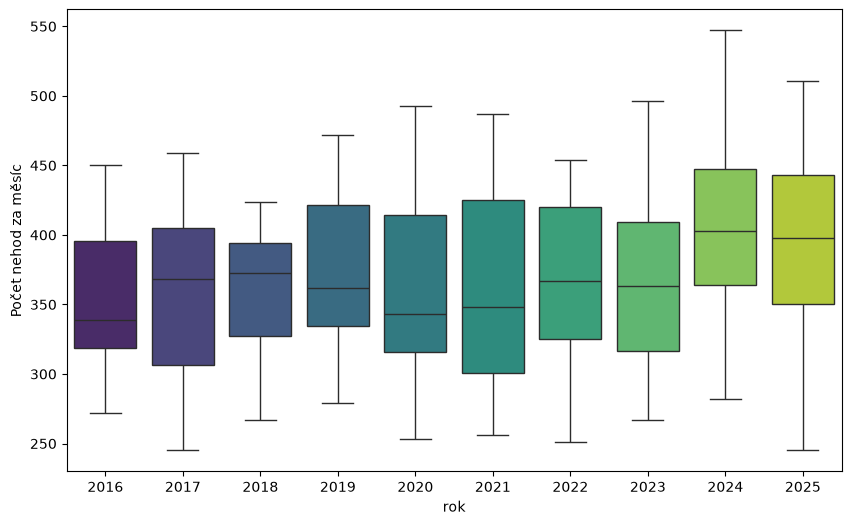

In [22]:
statMesice = df.groupby(['rok', 'mesic']).size().reset_index(name='pocetNehod')


plt.figure(figsize=(10, 6))
sns.boxplot(data=statMesice, x='rok', y='pocetNehod',palette="viridis")

plt.title('')
plt.ylabel('Počet nehod za měsíc')
plt.show()

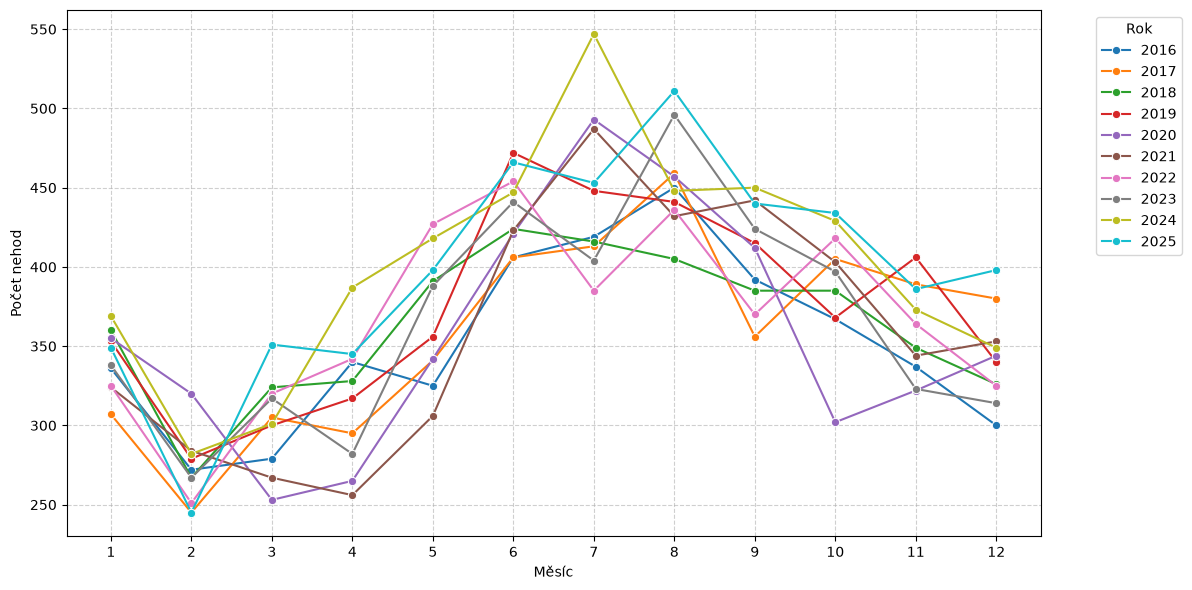

In [29]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=statMesice, x='mesic', y='pocetNehod', hue='rok', marker='o', palette='tab10')


plt.xlabel('Měsíc')
plt.ylabel('Počet nehod')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Rok', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [31]:
statMesice

,rok,mesic,pocetNehod
0,2016,1,336
1,2016,2,272
2,2016,3,279
3,2016,4,340
4,2016,5,325
...,...,...,...
115,2025,8,511
116,2025,9,440
117,2025,10,434
118,2025,11,386


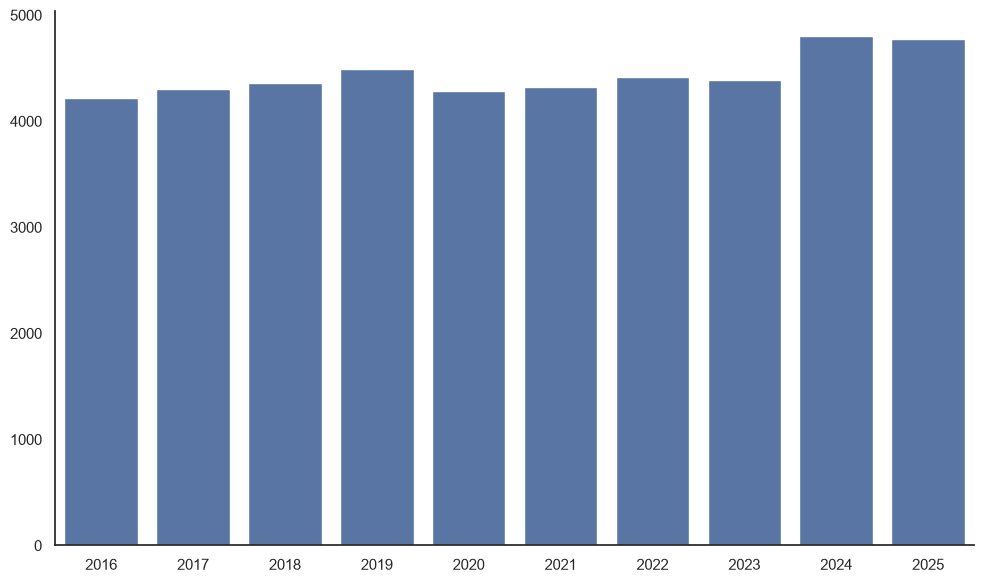

In [43]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='rok')

plt.title('', fontsize=14)
plt.xlabel('', fontsize=12)
plt.ylabel('', fontsize=12)
sns.despine()
plt.tight_layout()

plt.show()

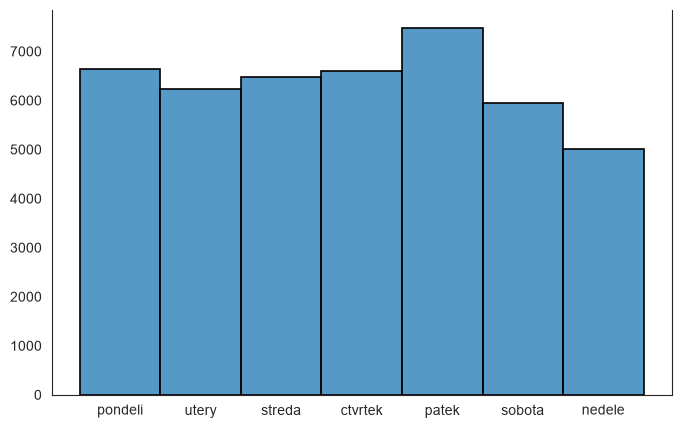

In [35]:


poradi = ['pondeli','utery','streda','ctvrtek','patek','sobota','nedele']

df['den'] = pd.Categorical(df['den'], categories=poradi, ordered=True)
sns.set_style("white")

plt.figure(figsize=(8, 5))

ax = sns.histplot(
    data=df, 
    x='den', 
    hue_order=poradi,
    edgecolor='black',
    linewidth=1.2,)

sns.despine(top=True, right=False, left=False, bottom=False)
plt.title("")
plt.xlabel("")
plt.ylabel("")


plt.show()

Text(0, 0.5, '')

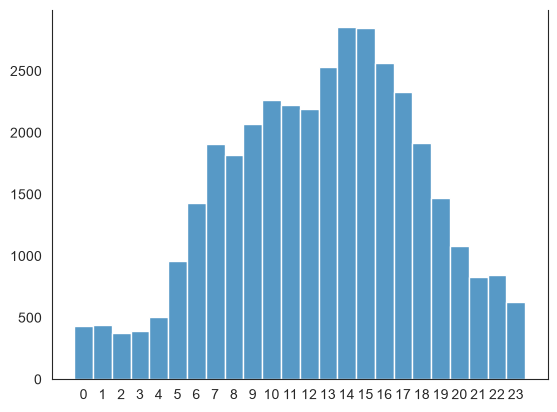

In [36]:

c="hodina"

df[c]=df[c].astype('Int64')
df=df.sort_values(c)
df[c]=df[c].astype("string")
sns.histplot(df[c])

sns.despine(top=True, right=False, left=False, bottom=False)
plt.title("")
plt.xlabel("")
plt.ylabel("")

In [37]:
dfCopy=df.copy()

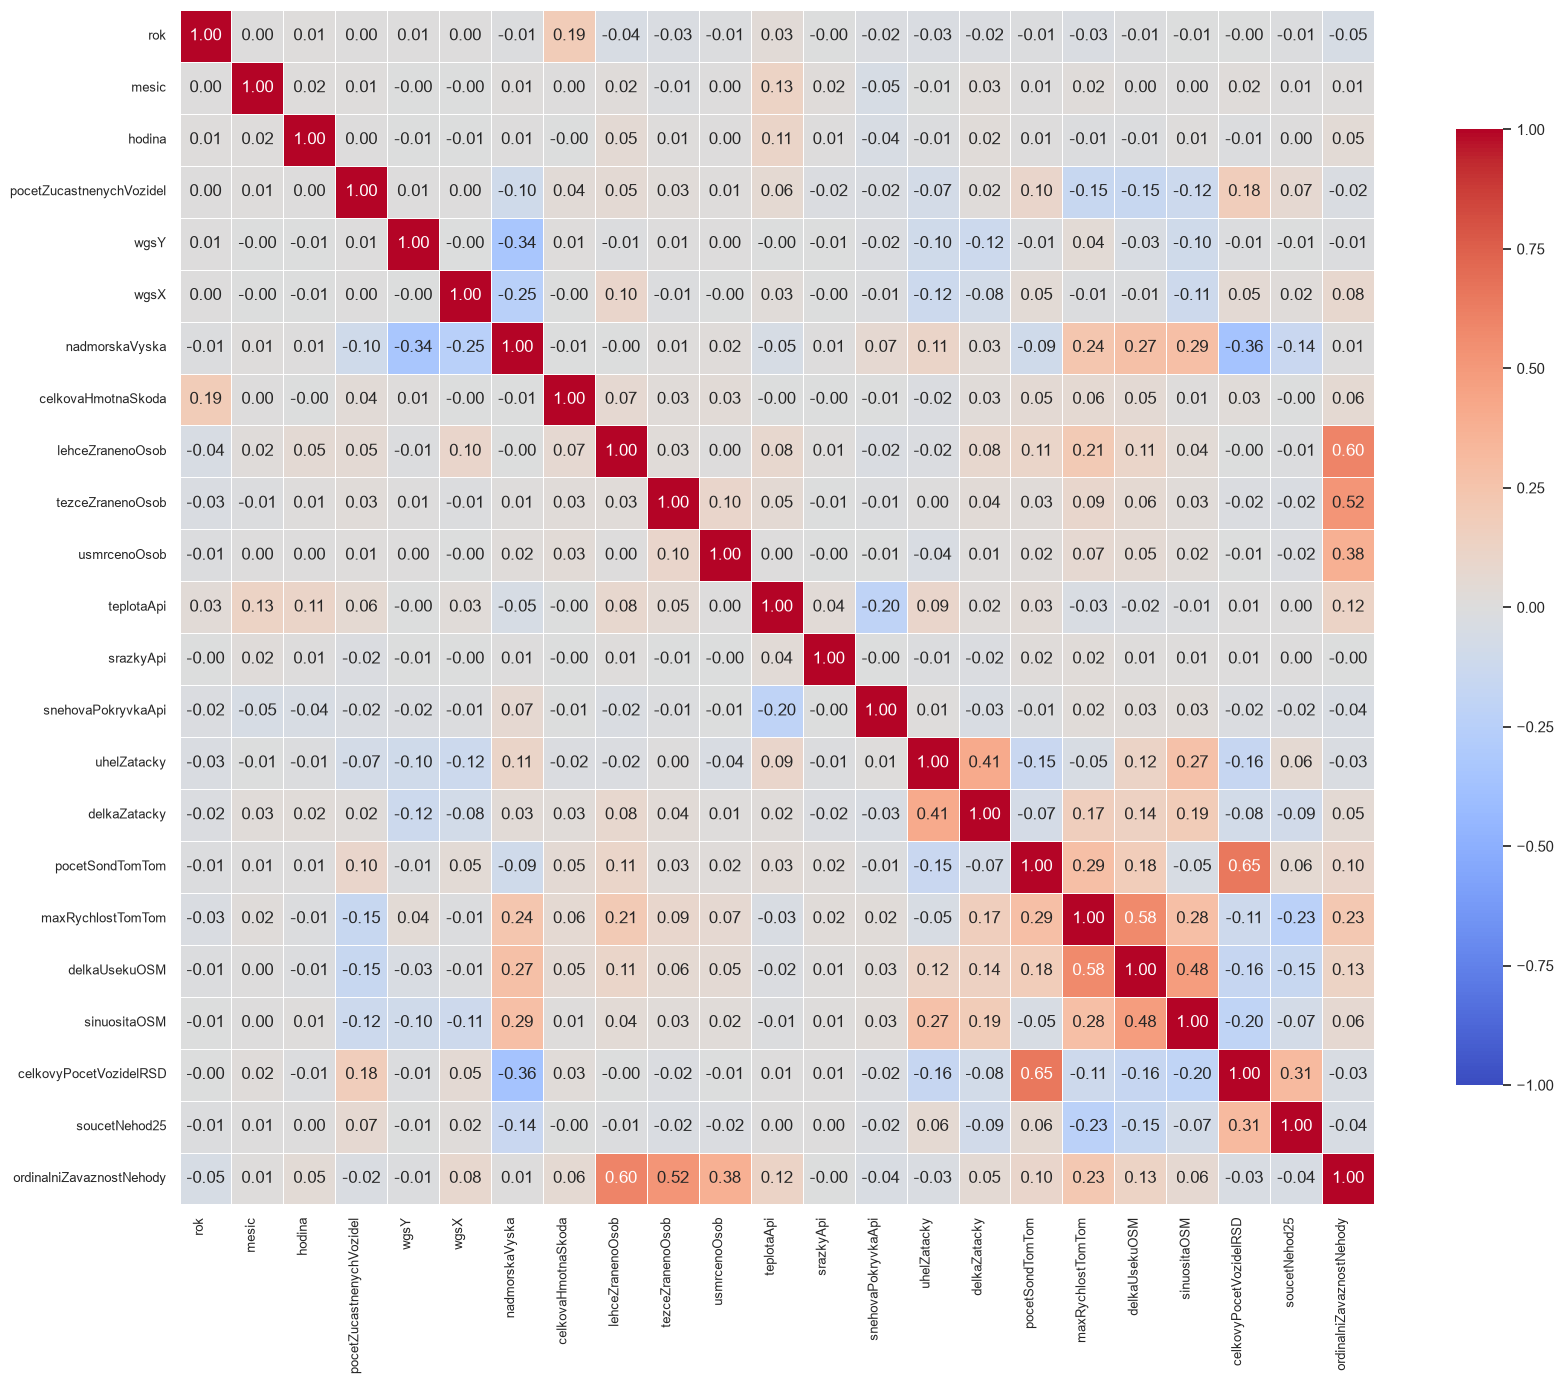

In [ ]:
columns = [
    "rok", "mesic", "hodina", "pocetZucastnenychVozidel", "wgsY", "wgsX",
    "nadmorskaVyska", "celkovaHmotnaSkoda", "lehceZranenoOsob", "tezceZranenoOsob",
    "usmrcenoOsob", "teplotaApi", "srazkyApi", "snehovaPokryvkaApi", "uhelZatacky",
    "delkaZatacky", "pocetSondTomTom", "maxRychlostTomTom", "delkaUsekuOSM",
    "sinuositaOSM", "celkovyPocetVozidelRSD", "soucetNehod25", "ordinalniZavaznostNehody"
]
severityMapping = {
    'pouzeHmotnaSkoda': 0,
    'lehceZavaznaNehoda': 1,
    'zavaznaNehoda': 2,
    'smrtelnaNehoda': 3
}

dfCopy["ordinalniZavaznostNehody"]=dfCopy['zavaznostNehody'].map(severityMapping)

dfCopy=dfCopy[columns]

corr = dfCopy.corr()


plt.figure(figsize=(18, 14))


sns.set_theme(style="white")

heatmap = sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=.5,
    square=True,  
    cbar_kws={"shrink": .8} 
)


# Nastavení popisků os (převzato ze seznamu columns)
heatmap.set_xticklabels(columns, rotation=90, ha='right', fontsize=9)
heatmap.set_yticklabels(columns, rotation=0, fontsize=9)


plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

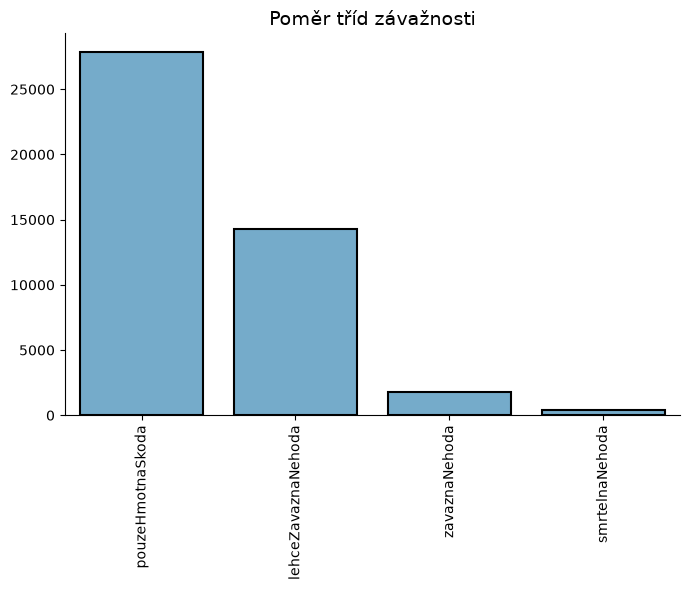

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

order= [
    'pouzeHmotnaSkoda',
    'lehceZavaznaNehoda',
    'zavaznaNehoda',
    'smrtelnaNehoda'
]

plt.figure(figsize=(7, 6))


sns.countplot(
    data=df, 
    x='zavaznostNehody', 
    color="#67afd8", 
    order=order,    
    edgecolor='black', 
    linewidth=1.5
)

plt.title('Poměr tříd závažnosti', fontsize=14)
plt.xlabel('')
plt.ylabel('')


plt.xticks(rotation=90)

sns.despine()

plt.tight_layout()
plt.show()

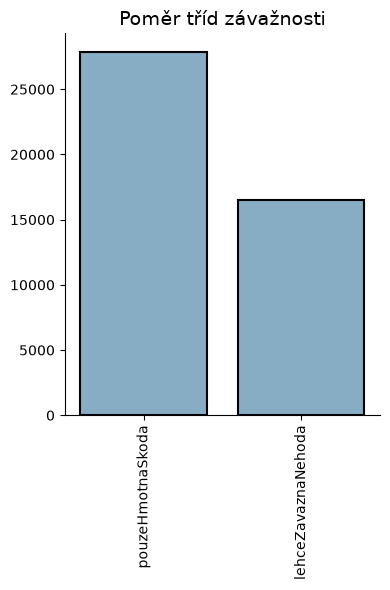

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
dfCopy=df.copy()

dfCopy.loc[dfCopy.zavaznostNehody=="zavaznaNehoda","zavaznostNehody"]="lehceZavaznaNehoda"
dfCopy.loc[dfCopy.zavaznostNehody=="smrtelnaNehoda","zavaznostNehody"]="lehceZavaznaNehoda"

order = [
    'pouzeHmotnaSkoda',
    'lehceZavaznaNehoda'
]

plt.figure(figsize=(4, 6))

sns.countplot(
    data=dfCopy, 
    x='zavaznostNehody', 
    color="#7bb0cf", 
    order=order,    
    edgecolor='black', 
    linewidth=1.5
)

plt.title('Poměr tříd závažnosti', fontsize=14)
plt.xlabel('')
plt.ylabel('')

plt.xticks(rotation=90)

sns.despine()

plt.tight_layout()
plt.show()